# CaloDiffusion Electron — Final Technical Actions

## Targeted decoder replay • fixed-cell hotspot investigation • deep-shower review • provenance record

This notebook completes the remaining focused electron diagnostics using the **three existing electron fidelity ZIPs**. It does not retrain CaloDiffusion and does not launch a new three-seed fidelity study.

### What it does
1. Re-check that all three fidelity runs use the same reference events, baseline donors, checkpoint, source revision and analysis cutoff.
2. Inspect the high-response electron shower (response ≈ 1.373) at native-cell level.
3. **Optionally replay the exact original 16-event generation batch** containing that shower, using the original generation seed, chunk boundary, checkpoint and source revision. This is required to inspect the pre-decoder denoised states; the existing ZIP files do not contain those states.
4. Test the low-response event's hotspot at native cell 1565, including neighbouring cells and recurrence across seeds, energy windows, reference and scale-only samples.
5. Revisit the three deep-shower candidates against the fixed reference sample, with layer-by-layer profiles and reference percentiles.
6. Create a provenance checklist for questions that only the model/data provider or guide can answer.
7. Export tables, plots, replay diagnostics and a concise report.

### Important limits
- An exact replay is attempted only if the source revision and checkpoint hashes match the manifests. If the exact checkpoint cannot be retrieved, the non-replay analyses still run and the replay is marked unavailable.
- The replay re-generates **one 16-event batch** solely to recover intermediate model-space states for the known high-response event. It is not a new fidelity campaign.
- A response above one is mathematically allowed by the per-cell inverse transform used here; that does not make an extreme response physically acceptable.
- Outlier sensitivity tests never remove events from the primary sample statistics.
- The reference/checkpoint independence question cannot be decided from these ZIPs. The notebook records the evidence and leaves the confirmation to your guide.

### Inputs
Upload the three electron fidelity ZIPs for generation seeds `20261110`, `20261111`, and `20261112`.

In [ ]:
# 1. Imports and fixed study settings
import io, os, sys, json, math, hashlib, zipfile, subprocess, random, contextlib, warnings, textwrap
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from IPython.display import display, Markdown

EXPECTED_SEEDS = (20261110, 20261111, 20261112)
STRATA = ("8-12GeV", "40-60GeV", "80-120GeV")
ANALYSIS_CUT_GEV = 1.51e-5  # 15.1 keV
EXPECTED_REVISION = "00ebcc3534fc25eee0fe15361483833e0bca34e7"
EXPECTED_PARTITION_SEED = 20261101
EXPECTED_BASELINE_SEED = 20261102
EXPECTED_ANALYSIS_SEED = 20261103
EXPECTED_CHECKPOINT_SHA256 = "cb62afae47997307842a3f7683fcbeffdbfc7db7a7a86bb93c83063385184dee"
EXPECTED_REFERENCE_SHA256 = "bf73fcfa2269b3e0e0a24d0bccdeb052369fdd5ead2690a598f5e18066c6bd9f"
EXPECTED_SOURCE_SHA256 = {
    "calodiff_probe.py": "bdbd39c507134bacb1352e528260315805385809a5b9fcdf8bfae530a97f257d",
    "paper_code/scripts/CaloDiffu.py": "ca6f4afb913f0cc6ead100ee54762891f851f7a40358f0d2fc3c1e8281526a97",
    "paper_code/scripts/consts.py": "3fc6312ff243d3f80f1fefc69ce27cf975713652826141fe2c1ef7e7381c6244",
    "paper_code/scripts/models.py": "8138376149ce1134609455ca8c29a043906b1a2b6a948f490d57c824fbe807d1",
    "paper_code/scripts/utils.py": "d34325c1fa5029fa436359b8893095e11c12bdb70a27a165b9b71c9e2164ea9e",
    "paper_code/configs/config_dataset2.json": "aada27339b2ee253348d42b5f641da1d857add005c5598fe868d20359f9dc4c9",
    "paper_code/CaloChallenge/code/binning_dataset_2.xml": "e4e3b6fe0d7934da3a82b716e64129b08374b0aaf5c10b77435d5d520c9b1b86",
}

N_LAYERS, N_ANGLES, N_RADIAL = 45, 16, 9
N_CELLS = N_LAYERS * N_ANGLES * N_RADIAL
HOTSPOT_COORD = (10, 13, 8)
HOTSPOT_INDEX = int(np.ravel_multi_index(HOTSPOT_COORD, (N_LAYERS, N_ANGLES, N_RADIAL), order="C"))
HOTSPOT_THRESHOLDS_GEV = (0.1, 0.25, 0.5, 0.8, 1.0)

OUTPUT_DIR = Path("/content/electron_final_actions")
TABLE_DIR = OUTPUT_DIR / "tables"
FIG_DIR = OUTPUT_DIR / "figures"
for p in (OUTPUT_DIR, TABLE_DIR, FIG_DIR): p.mkdir(parents=True, exist_ok=True)

print("Analysis cutoff:", ANALYSIS_CUT_GEV, "GeV")
print("Native shape:", (N_LAYERS, N_ANGLES, N_RADIAL), "=", N_CELLS, "cells")
print("Fixed hotspot:", HOTSPOT_COORD, "-> native index", HOTSPOT_INDEX)

Analysis cutoff: 1.51e-05 GeV
Native shape: (45, 16, 9) = 6480 cells
Fixed hotspot: (10, 13, 8) -> native index 1565


## 1. Upload and load the three fidelity archives

Upload the original fidelity ZIPs, not the previous technical-investigation ZIP. We need the full native arrays to re-check hotspot recurrence and reconstruct the exact high-response generation batch.

In [ ]:
# 2. Upload exactly three fidelity ZIP files (Google Colab)
from google.colab import files
uploaded = files.upload()
zip_uploads = {name: payload for name, payload in uploaded.items() if name.lower().endswith(".zip")}
if len(zip_uploads) != 3:
    raise ValueError(f"Expected exactly three fidelity ZIPs; received {len(zip_uploads)}.")
print("Uploaded archives:")
for name in zip_uploads: print(" -", name)

Saving validated_calo_controlled_electron_partition20261101_generation20261110_20261110T114741139357Z_fidelity_20261110T122654678596Z.zip to validated_calo_controlled_electron_partition20261101_generation20261110_20261110T114741139357Z_fidelity_20261110T122654678596Z.zip
Saving validated_calo_controlled_electron_partition20261101_generation20261111_20261110T122815545026Z_fidelity_20261110T130201775779Z.zip to validated_calo_controlled_electron_partition20261101_generation20261111_20261110T122815545026Z_fidelity_20261110T130201775779Z.zip
Saving validated_calo_controlled_electron_partition20261101_generation20261112_20261110T130357961245Z_fidelity_20261110T140251286095Z.zip to validated_calo_controlled_electron_partition20261101_generation20261112_20261110T130357961245Z_fidelity_20261110T140251286095Z.zip
Uploaded archives:
 - validated_calo_controlled_electron_partition20261101_generation20261110_20261110T114741139357Z_fidelity_20261110T122654678596Z.zip
 - validated_calo_controlled_el

In [ ]:
# 3. Archive readers

def member_exact(zf, member):
    hits = [n for n in zf.namelist() if n == member]
    if len(hits) != 1:
        raise ValueError(f"Expected one archive member {member!r}; found {len(hits)}")
    return hits[0]

def read_json_member(zf, member):
    return json.loads(zf.read(member).decode("utf-8"))

def read_csv_member(zf, member):
    return pd.read_csv(io.BytesIO(zf.read(member)))

def read_npz_member(zf, member):
    with np.load(io.BytesIO(zf.read(member)), allow_pickle=False) as a:
        return {k: a[k].copy() for k in a.files}

runs = {}
for archive_name, payload in zip_uploads.items():
    zf = zipfile.ZipFile(io.BytesIO(payload))
    manifest_member = next((n for n in zf.namelist() if n.endswith("/manifest.json")), None)
    if manifest_member is None: raise ValueError(f"No manifest.json in {archive_name}")
    root = manifest_member.rsplit("/", 1)[0]
    manifest = read_json_member(zf, manifest_member)
    seed = int(manifest["seed_streams"]["generation_seed"])
    if seed in runs: raise ValueError(f"Duplicate generation seed {seed}")
    geometry = read_json_member(zf, f"{root}/electron_geometry.json")

    data = {}
    for window in STRATA:
        prefix = f"{root}/arrays/electron_{window}_"
        data[window] = {
            "reference": read_npz_member(zf, prefix + "reference_run-1.npz"),
            "generator_run0": read_npz_member(zf, prefix + "generator_run0.npz"),
            "generator_run1": read_npz_member(zf, prefix + "generator_run1.npz"),
            "scale_only": read_npz_member(zf, prefix + "scale_only_run-1.npz"),
        }

    tables = {
        "partitions": read_csv_member(zf, f"{root}/tables/electron_event_partitions.csv"),
        "donors": {
            w: read_csv_member(zf, f"{root}/tables/electron_{w}_scale_donors.csv")
            for w in STRATA
        },
    }
    runs[seed] = {
        "archive_name": archive_name, "zip": zf, "root": root,
        "manifest": manifest, "geometry": geometry,
        "data": data, "tables": tables,
    }

if tuple(sorted(runs)) != EXPECTED_SEEDS:
    raise ValueError(f"Expected seeds {EXPECTED_SEEDS}; found {tuple(sorted(runs))}")
print("Loaded generation seeds:", sorted(runs))

Loaded generation seeds: [20261110, 20261111, 20261112]


## 2. Re-verify the controlled design

This guards against interpreting a diagnostic that accidentally mixes partitions or checkpoints. The fixed-reference and scale-only arrays should be byte-for-byte identical across the three generation seeds.

In [ ]:
# 4. Compatibility, exact partition and donor checks
compat_rows = []
base = runs[EXPECTED_SEEDS[0]]["manifest"]
for seed in EXPECTED_SEEDS:
    m = runs[seed]["manifest"]
    checks = {
        "electron_only": m.get("particles") == ["electron"],
        "repository_revision": m.get("revision") == EXPECTED_REVISION,
        "checkpoint_hash": m["checkpoints"]["electron"]["sha256"] == EXPECTED_CHECKPOINT_SHA256,
        "reference_hash": m["reference_files"]["electron"]["sha256"] == EXPECTED_REFERENCE_SHA256,
        "partition_seed": m["seed_streams"].get("partition_seed") == EXPECTED_PARTITION_SEED,
        "baseline_seed": m["seed_streams"].get("baseline_seed") == EXPECTED_BASELINE_SEED,
        "analysis_seed": m["seed_streams"].get("analysis_seed") == EXPECTED_ANALYSIS_SEED,
        "analysis_cut": np.isclose(m["analysis_cut_GeV_overrides"]["electron"], ANALYSIS_CUT_GEV),
        "same_checkpoint_as_first": m["checkpoints"]["electron"]["sha256"] == base["checkpoints"]["electron"]["sha256"],
        "same_reference_as_first": m["reference_files"]["electron"]["sha256"] == base["reference_files"]["electron"]["sha256"],
        "same_partition_hash_as_first": m["partition_sha256"]["electron"] == base["partition_sha256"]["electron"],
        "same_donor_hashes_as_first": m["scale_donor_sha256"]["electron"] == base["scale_donor_sha256"]["electron"],
        "same_source_hashes_as_first": m.get("source_sha256") == base.get("source_sha256"),
    }
    for k, v in checks.items(): compat_rows.append({"generation_seed": seed, "check": k, "passed": bool(v)})
compat_df = pd.DataFrame(compat_rows)
display(compat_df.pivot(index="check", columns="generation_seed", values="passed"))

for seed in EXPECTED_SEEDS[1:]:
    pd.testing.assert_frame_equal(
        runs[seed]["tables"]["partitions"].sort_values(["stratum", "partition", "row"]).reset_index(drop=True),
        runs[EXPECTED_SEEDS[0]]["tables"]["partitions"].sort_values(["stratum", "partition", "row"]).reset_index(drop=True),
        check_dtype=False,
    )
    for w in STRATA:
        pd.testing.assert_frame_equal(
            runs[seed]["tables"]["donors"][w].sort_values("target_id").reset_index(drop=True),
            runs[EXPECTED_SEEDS[0]]["tables"]["donors"][w].sort_values("target_id").reset_index(drop=True),
            check_dtype=False,
        )
        for method in ("reference", "scale_only"):
            a = runs[EXPECTED_SEEDS[0]]["data"][w][method]
            b = runs[seed]["data"][w][method]
            for key in ("native", "energy", "event_id"):
                if not np.array_equal(a[key], b[key]):
                    raise AssertionError(f"{method}/{key} differs: {w}, seed {seed}")

if not compat_df["passed"].all():
    raise AssertionError("A controlled-run compatibility check failed. Stop and inspect manifests.")
print("PASS: reference partitions, reference arrays, donor selections and scale-only arrays match across seeds.")
print("Reference/checkpoint independence:", [runs[s]["manifest"].get("reference_is_unseen_by_checkpoint") for s in EXPECTED_SEEDS])

generation_seed,20261110,20261111,20261112
check,,,
analysis_cut,True,True,True
analysis_seed,True,True,True
baseline_seed,True,True,True
checkpoint_hash,True,True,True
electron_only,True,True,True
partition_seed,True,True,True
reference_hash,True,True,True
repository_revision,True,True,True
same_checkpoint_as_first,True,True,True


PASS: reference partitions, reference arrays, donor selections and scale-only arrays match across seeds.
Reference/checkpoint independence: [False, False, False]


## 3. Geometry and event-observable helpers

Electron native arrays use `(45, 16, 9)` in C-order: layer, angular bin, radial bin. The flat index is `((layer*16)+angle)*9+radial`. This is the mapping verified in the separate electron preflight.

In [ ]:
# 5. Reconstruct geometry metadata from the fidelity archives
geometry = runs[EXPECTED_SEEDS[0]]["geometry"]
layer_ids = np.asarray(geometry["layer_ids"], dtype=int)
n_angles = np.asarray(geometry["n_angles"], dtype=int)
radial_edges = [np.asarray(v, dtype=float) for v in geometry["radial_edges"]]
assert len(layer_ids) == N_LAYERS and np.all(n_angles == N_ANGLES)
assert len(radial_edges) == N_LAYERS and all(len(v) == N_RADIAL + 1 for v in radial_edges)

radial_centres = np.stack([0.5 * (e[:-1] + e[1:]) for e in radial_edges])
R_GRID = np.broadcast_to(radial_centres[:, None, :], (N_LAYERS, N_ANGLES, N_RADIAL))
cell_map = pd.DataFrame([
    {
        "native_index": int(np.ravel_multi_index((L, A, R), (N_LAYERS, N_ANGLES, N_RADIAL), order="C")),
        "layer_ordinal": L, "layer_id": int(layer_ids[L]), "angle_bin": A, "radial_bin": R,
        "r_low_XML": float(radial_edges[L][R]), "r_high_XML": float(radial_edges[L][R+1]),
    }
    for L in range(N_LAYERS) for A in range(N_ANGLES) for R in range(N_RADIAL)
])
assert len(cell_map) == N_CELLS
hot_cell_meta = cell_map.loc[cell_map.native_index == HOTSPOT_INDEX].iloc[0]
assert (int(hot_cell_meta.layer_ordinal), int(hot_cell_meta.angle_bin), int(hot_cell_meta.radial_bin)) == HOTSPOT_COORD
print("Hotspot geometry:")
display(hot_cell_meta.to_frame("value"))

Hotspot geometry:


,value
native_index,1565.00
layer_ordinal,10.00
layer_id,10.00
angle_bin,13.00
radial_bin,8.00
r_low_XML,37.20
r_high_XML,41.85


In [ ]:
# 6. Shared physical-observable helpers

def threshold_native(native):
    x = np.asarray(native, dtype=np.float64)
    if x.ndim != 1 or x.size != N_CELLS:
        raise ValueError(f"Expected one native shower with {N_CELLS} cells")
    if not np.isfinite(x).all():
        raise ValueError("Non-finite native shower values")
    return np.where(x >= ANALYSIS_CUT_GEV, x, 0.0)


def event_metrics(native, incident_energy):
    a = threshold_native(native)
    cube = a.reshape(N_LAYERS, N_ANGLES, N_RADIAL)
    total = float(a.sum())
    E = float(incident_energy)
    if E <= 0 or not np.isfinite(E): raise ValueError("Invalid incident energy")
    layer_energy = cube.sum(axis=(1, 2))
    if total > 0:
        depth = float(np.dot(np.arange(N_LAYERS), layer_energy) / total)
        r_mean = float(np.sum(cube * R_GRID) / total)
        r2 = float(np.sum(cube * (R_GRID ** 2)) / total)
        r_rms = float(np.sqrt(max(r2, 0.0)))
        r_sigma = float(np.sqrt(max(r2 - r_mean**2, 0.0)))
        layer_fraction = layer_energy / total
    else:
        depth = r_rms = r_sigma = np.nan
        layer_fraction = np.full(N_LAYERS, np.nan)
    positive = np.sort(a[a > 0])[::-1]
    return {
        "deposit_GeV": total, "response": total/E,
        "occupancy": float(np.count_nonzero(a) / N_CELLS),
        "depth_layer": depth, "r_rms_XML": r_rms, "r_sigma_XML": r_sigma,
        "max_cell_GeV": float(a.max()),
        "top5_fraction": float(positive[:5].sum()/total) if total > 0 else np.nan,
        "layer_energy_GeV": layer_energy,
        "layer_fraction": layer_fraction,
        "native_after_cut": a,
    }


def percentile_rank(values, value):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    return 100.0 * float(np.mean(x <= value)) if len(x) else np.nan


def wilson_interval(k, n, z=1.959963984540054):
    if n <= 0: return np.nan, np.nan
    p = k/n
    den = 1 + z*z/n
    centre = (p + z*z/(2*n))/den
    half = z*np.sqrt((p*(1-p)/n) + z*z/(4*n*n))/den
    return max(0.0, centre-half), min(1.0, centre+half)

print("Helpers ready. Cutoff:", ANALYSIS_CUT_GEV, "GeV")

Helpers ready. Cutoff: 1.51e-05 GeV


## 4. Candidate identification and high-response native-cell audit

Candidate identity is keyed by generation seed, energy window, repeat and row. It is not matched event-by-event to a Geant4 shower; the same reference event supplies the incident-energy condition, not shower-level truth.

In [ ]:
# 7. Resolve the five previously selected candidate showers
CANDIDATES = [
    {"label":"high_response_1p373", "seed":20261111, "window":"8-12GeV", "run":0, "row":61},
    {"label":"low_response_broad_radial_0p467", "seed":20261111, "window":"8-12GeV", "run":0, "row":200},
    {"label":"deep_8_12", "seed":20261110, "window":"8-12GeV", "run":1, "row":58},
    {"label":"deep_40_60", "seed":20261110, "window":"40-60GeV", "run":0, "row":113},
    {"label":"deep_80_120", "seed":20261112, "window":"80-120GeV", "run":1, "row":48},
]

candidate_data = {}
for c in CANDIDATES:
    arr = runs[c["seed"]]["data"][c["window"]][f"generator_run{c['run']}"]
    row = c["row"]
    native = arr["native"][row].astype(np.float64)
    energy = float(arr["energy"][row])
    event_id = str(arr["event_id"][row])
    obs = event_metrics(native, energy)
    candidate_data[c["label"]] = {**c, "native":native, "energy":energy, "event_id":event_id, "obs":obs}

candidate_summary = []
for label, c in candidate_data.items():
    o = c["obs"]
    candidate_summary.append({
        "label": label, "seed": c["seed"], "window": c["window"], "run": c["run"], "row": c["row"],
        "event_id": c["event_id"], "incident_energy_GeV": c["energy"],
        "deposit_GeV": o["deposit_GeV"], "response": o["response"], "occupancy": o["occupancy"],
        "depth_layer": o["depth_layer"], "r_rms_XML": o["r_rms_XML"],
        "max_cell_GeV": o["max_cell_GeV"], "top5_fraction": o["top5_fraction"],
    })
candidate_summary_df = pd.DataFrame(candidate_summary)
display(candidate_summary_df)

,label,seed,window,run,row,event_id,incident_energy_GeV,deposit_GeV,response,occupancy,depth_layer,r_rms_XML,max_cell_GeV,top5_fraction
0,high_response_1p373,20261111,8-12GeV,0,61,gen:electron:8-12GeV:0:61,9.771068,13.418580,1.373297,0.065123,4.665407,11.587820,2.545314,0.379329
1,low_response_broad_radial_0p467,20261111,8-12GeV,0,200,gen:electron:8-12GeV:0:200,8.448531,3.942201,0.466614,0.038889,7.640819,23.429949,0.882544,0.335316
2,deep_8_12,20261110,8-12GeV,1,58,gen:electron:8-12GeV:1:58,10.399022,7.643424,0.735014,0.079167,22.527751,7.127536,0.107021,0.054300
3,deep_40_60,20261110,40-60GeV,0,113,gen:electron:40-60GeV:0:113,43.047789,32.110019,0.745916,0.218519,16.845594,12.390800,0.414028,0.054312
4,deep_80_120,20261112,80-120GeV,1,48,gen:electron:80-120GeV:1:48,114.937406,90.051398,0.783482,0.347685,16.712123,11.023454,0.779867,0.027739


In [ ]:
# 8. High-response shower: inspect largest native-cell deposits
high = candidate_data["high_response_1p373"]
high_native = high["obs"]["native_after_cut"]
high_cube = high_native.reshape(N_LAYERS, N_ANGLES, N_RADIAL)
rank = np.argsort(high_native)[::-1][:20]
high_top_cells = cell_map.set_index("native_index").loc[rank].reset_index()
high_top_cells["energy_GeV"] = high_native[rank]
high_top_cells["fraction_of_total"] = high_native[rank] / high_native.sum()
display(high_top_cells.head(15))

largest = float(high_native.max())
without_top1 = high_native.copy(); without_top1[int(np.argmax(high_native))] = 0.0
without_top5 = high_native.copy(); without_top5[rank[:5]] = 0.0
high_sensitivity = pd.DataFrame([
    {"case":"original", "deposit_GeV":high_native.sum(), "response":high_native.sum()/high["energy"],
     "r_rms_XML":event_metrics(high["native"], high["energy"])["r_rms_XML"]},
    {"case":"remove_largest_cell_diagnostic_only", "deposit_GeV":without_top1.sum(), "response":without_top1.sum()/high["energy"],
     "r_rms_XML":float(np.sqrt(np.sum(without_top1 * R_GRID.reshape(-1)**2)/without_top1.sum())) if without_top1.sum()>0 else np.nan},
    {"case":"remove_top_5_cells_diagnostic_only", "deposit_GeV":without_top5.sum(), "response":without_top5.sum()/high["energy"], "r_rms_XML":np.nan},
])
print("High-response sensitivity (diagnostic only; do not remove events from fidelity metrics):")
display(high_sensitivity)

,native_index,layer_ordinal,layer_id,angle_bin,radial_bin,r_low_XML,r_high_XML,energy_GeV,fraction_of_total
0,118,0,0,13,1,4.65,9.30,2.545314,0.189686
1,831,5,5,12,3,13.95,18.60,1.107875,0.082563
2,117,0,0,13,0,0.00,4.65,1.050020,0.078251
3,2265,15,15,11,6,27.90,32.55,0.203844,0.015191
4,1624,11,11,4,4,18.60,23.25,0.183007,0.013638
5,855,5,5,15,0,0.00,4.65,0.156635,0.011673
6,758,5,5,4,2,9.30,13.95,0.135395,0.010090
7,801,5,5,9,0,0.00,4.65,0.132733,0.009892
8,513,3,3,9,0,0.00,4.65,0.129710,0.009666
9,830,5,5,12,2,9.30,13.95,0.129427,0.009645


High-response sensitivity (diagnostic only; do not remove events from fidelity metrics):


,case,deposit_GeV,response,r_rms_XML
0,original,13.418580,1.373297,11.587820
1,remove_largest_cell_diagnostic_only,10.873266,1.112802,12.422638
2,remove_top_5_cells_diagnostic_only,8.328520,0.852365,NaN


## 5. Exact high-response sampler replay (optional but recommended)

The fidelity ZIP contains the decoded native array, but not the original pre-decoder tensor. The cell below fetches the exact source revision and checkpoint recorded in the run manifest, verifies their hashes, and reconstructs the **same 16-event batch** that contained row 61:

- Original generation seed: `20261111`.
- Window: `8-12GeV`, repeat `0`.
- Batch size: `16`; row 61 is in chunk `48:64`, local position `13`.
- The exact seed derivation from the validation notebook is repeated.

If hashes match, it captures the model-space clean estimate (`x0_hat`) at each reverse-diffusion step, decodes it using the checkpoint's inverse transform, and compares the final native array with the archived shower. This is a targeted 16-shower replay, not a new fidelity run.

In [ ]:
# 9. Fetch the exact repository revision and checkpoint (Colab)
# If GitHub/Git LFS is unavailable, this cell records the reason and later cells still run.
REPLAY_AVAILABLE = False
REPLAY_SETUP_ERROR = None
REPO_URL = "https://github.com/Vishal21501/gen-hep-notebooks.git"
REPLAY_REPO = Path("/content/calo_electron_exact_replay_repo")
EXPECTED_CHECKPOINT_REL = "paper_code/trained_models/dataset2.pth"

try:
    clone_env = dict(os.environ, GIT_LFS_SKIP_SMUDGE="1")
    if not (REPLAY_REPO / ".git").exists():
        if REPLAY_REPO.exists():
            raise RuntimeError(f"{REPLAY_REPO} exists but is not a Git checkout; use a fresh runtime or remove it deliberately.")
        subprocess.run([
            "git", "clone", "--depth", "1", "--filter=blob:none", "--sparse",
            "--branch", "main", REPO_URL, str(REPLAY_REPO)
        ], check=True, env=clone_env)
        subprocess.run(["git", "-C", str(REPLAY_REPO), "sparse-checkout", "set", "capstone/calodiffusion"], check=True)

    subprocess.run(["git", "-C", str(REPLAY_REPO), "fetch", "--depth", "1", "origin", EXPECTED_REVISION], check=True, env=clone_env)
    subprocess.run(["git", "-C", str(REPLAY_REPO), "checkout", "--detach", EXPECTED_REVISION], check=True)
    ROOT = REPLAY_REPO / "capstone" / "calodiffusion"
    actual_revision = subprocess.check_output(["git", "-C", str(REPLAY_REPO), "rev-parse", "HEAD"], text=True).strip()
    if actual_revision != EXPECTED_REVISION:
        raise RuntimeError(f"Repository revision mismatch: {actual_revision}")

    # Fetch only the electron checkpoint if it is a Git LFS pointer.
    checkpoint_path = ROOT / EXPECTED_CHECKPOINT_REL
    def is_lfs_pointer(path):
        if not path.is_file(): return False
        with path.open("rb") as f: return f.read(160).startswith(b"version https://git-lfs.github.com/spec/v1")

    if is_lfs_pointer(checkpoint_path) or not checkpoint_path.exists():
        has_lfs = subprocess.run(["git", "lfs", "version"], capture_output=True).returncode == 0
        if not has_lfs:
            subprocess.run(["apt-get", "update", "-qq"], check=True)
            subprocess.run(["apt-get", "install", "-y", "-qq", "git-lfs"], check=True)
        subprocess.run(["git", "-C", str(REPLAY_REPO), "lfs", "install", "--local"], check=True)
        subprocess.run([
            "git", "-C", str(REPLAY_REPO), "lfs", "pull",
            "--include=" + "capstone/calodiffusion/" + EXPECTED_CHECKPOINT_REL,
            "--exclude="
        ], check=True)

    if not checkpoint_path.is_file() or is_lfs_pointer(checkpoint_path):
        raise FileNotFoundError("Electron checkpoint is missing or remains an LFS pointer.")

    def sha256_file(path):
        h = hashlib.sha256()
        with open(path, "rb") as f:
            for b in iter(lambda: f.read(4 * 2**20), b""): h.update(b)
        return h.hexdigest()

    actual_checkpoint_sha = sha256_file(checkpoint_path)
    if actual_checkpoint_sha != EXPECTED_CHECKPOINT_SHA256:
        raise RuntimeError(f"Checkpoint hash mismatch: {actual_checkpoint_sha}")

    source_hash_rows = []
    for rel, expected in EXPECTED_SOURCE_SHA256.items():
        path = ROOT / rel
        if not path.is_file(): raise FileNotFoundError(path)
        actual = sha256_file(path)
        source_hash_rows.append({"file":rel, "expected_sha256":expected, "actual_sha256":actual, "matches":actual==expected})
        if actual != expected: raise RuntimeError(f"Source hash mismatch: {rel}")
    source_hash_df = pd.DataFrame(source_hash_rows)
    display(source_hash_df)

    # Preserve the intended file-role settings from the exact Dataset 2 config.
    # The repository file has a .json suffix, but this pinned revision may
    # contain a Python-literal dictionary (single-quoted keys/strings).
    # Try strict JSON first, then safely parse Python literals without eval().
    import ast
    config_path = ROOT / "paper_code/configs/config_dataset2.json"
    config_text = config_path.read_text(encoding="utf-8")
    try:
        dataset2_config = json.loads(config_text)
    except json.JSONDecodeError as json_error:
        try:
            dataset2_config = ast.literal_eval(config_text)
        except (ValueError, SyntaxError) as literal_error:
            raise RuntimeError(
                "Could not parse config_dataset2.json as JSON or a Python literal. "
                f"JSON error: {json_error}; literal error: {literal_error}"
            )
    if not isinstance(dataset2_config, dict):
        raise TypeError("Dataset 2 configuration must be a dictionary.")
    required_config_keys = ["FILES", "EVAL", "DATASET_NUM", "MAXDEP", "ECUT"]
    missing_config_keys = [k for k in required_config_keys if k not in dataset2_config]
    if missing_config_keys:
        raise KeyError(f"Missing Dataset 2 configuration keys: {missing_config_keys}")
    dataset2_config_evidence = {k: v for k, v in dataset2_config.items() if any(token in k.lower() for token in ("file", "eval", "train", "data"))}
    print("Dataset 2 configuration file-role fields:")
    print(json.dumps(dataset2_config_evidence, indent=2))

    # Import the exact wrapper only after source and checkpoint hashes pass.
    import torch
    os.environ["CALODIFF_DEVICE"] = "cuda" if torch.cuda.is_available() else "cpu"
    sys.path.insert(0, str(ROOT))
    import calodiff_probe as cp
    if Path(cp.__file__).resolve() != (ROOT / "calodiff_probe.py").resolve():
        raise RuntimeError("A different calodiff_probe module is already imported. Restart runtime and rerun this notebook.")
    REPLAY_AVAILABLE = True
    print("Exact source revision and checkpoint verified.")
    print("Device:", cp.DEVICE)
except Exception as exc:
    source_hash_df = pd.DataFrame()
    dataset2_config_evidence = {}
    REPLAY_SETUP_ERROR = repr(exc)
    REPLAY_AVAILABLE = False
    print("EXACT REPLAY UNAVAILABLE:", REPLAY_SETUP_ERROR)
    print("All archived-array, hotspot and deep-profile investigations can still proceed.")

,file,expected_sha256,actual_sha256,matches
0,calodiff_probe.py,bdbd39c507134bacb1352e528260315805385809a5b9fc...,bdbd39c507134bacb1352e528260315805385809a5b9fc...,True
1,paper_code/scripts/CaloDiffu.py,ca6f4afb913f0cc6ead100ee54762891f851f7a40358f0...,ca6f4afb913f0cc6ead100ee54762891f851f7a40358f0...,True
2,paper_code/scripts/consts.py,3fc6312ff243d3f80f1fefc69ce27cf975713652826141...,3fc6312ff243d3f80f1fefc69ce27cf975713652826141...,True
3,paper_code/scripts/models.py,8138376149ce1134609455ca8c29a043906b1a2b6a948f...,8138376149ce1134609455ca8c29a043906b1a2b6a948f...,True
4,paper_code/scripts/utils.py,d34325c1fa5029fa436359b8893095e11c12bdb70a27a1...,d34325c1fa5029fa436359b8893095e11c12bdb70a27a1...,True
5,paper_code/configs/config_dataset2.json,aada27339b2ee253348d42b5f641da1d857add005c5598...,aada27339b2ee253348d42b5f641da1d857add005c5598...,True
6,paper_code/CaloChallenge/code/binning_dataset_...,e4e3b6fe0d7934da3a82b716e64129b08374b0aaf5c10b...,e4e3b6fe0d7934da3a82b716e64129b08374b0aaf5c10b...,True


Dataset 2 configuration file-role fields:
{
  "FILES": [
    "dataset_2_1.hdf5"
  ],
  "EVAL": [
    "dataset_2_2.hdf5"
  ],
  "DATASET_NUM": 2,
  "TRAINING_OBJ": "noise_pred"
}
Exact source revision and checkpoint verified.
Device: cuda


In [ ]:
# 10. Reproduce the validation notebook's seed derivation and exact chunk
if REPLAY_AVAILABLE:
    import torch
    from scipy.special import expit
    from contextlib import redirect_stdout

    HIGH_SEED = 20261111
    HIGH_WINDOW = "8-12GeV"
    HIGH_RUN = 0
    HIGH_ROW = 61
    BATCH_SIZE_ORIGINAL = int(runs[HIGH_SEED]["manifest"]["config"]["batch_size"])
    SAMPLE_OFFSET = int(runs[HIGH_SEED]["manifest"]["config"]["sample_offset"])

    archived = runs[HIGH_SEED]["data"][HIGH_WINDOW]["generator_run0"]
    chunk_start = (HIGH_ROW // BATCH_SIZE_ORIGINAL) * BATCH_SIZE_ORIGINAL
    chunk_stop = min(chunk_start + BATCH_SIZE_ORIGINAL, len(archived["energy"]))
    local_target = HIGH_ROW - chunk_start
    replay_energies = archived["energy"][chunk_start:chunk_stop].astype(np.float64)
    archived_chunk = archived["native"][chunk_start:chunk_stop].astype(np.float32)

    # Exact named_seed implementation from the validation notebook.
    def named_seed(master_seed, *parts):
        text = "|".join(map(str, (master_seed, *parts)))
        return int(hashlib.sha256(text.encode()).hexdigest()[:8], 16)

    seed_base = named_seed(HIGH_SEED, "baseline", "electron", HIGH_WINDOW, HIGH_RUN)
    chunk_seed = named_seed(HIGH_SEED, seed_base, "chunk", chunk_start)

    print("Original batch:", chunk_start, ":", chunk_stop)
    print("Target local position:", local_target)
    print("Target event ID:", str(archived["event_id"][HIGH_ROW]))
    print("Target incident energy:", replay_energies[local_target], "GeV")
    print("Original chunk seed:", chunk_seed)
else:
    print("Skipping exact seed reconstruction because the exact source/checkpoint was not verified.")

Original batch: 48 : 64
Target local position: 13
Target event ID: gen:electron:8-12GeV:0:61
Target incident energy: 9.771068359375 GeV
Original chunk seed: 1466180748


In [ ]:
# 11. Load exact model and define the original decoder
if REPLAY_AVAILABLE:
    import torch
    import random
    import contextlib

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)
    if hasattr(torch.backends, "cuda"):
        torch.backends.cuda.matmul.allow_tf32 = False
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.allow_tf32 = False

    if torch.cuda.is_available():
        os.environ["CALODIFF_DEVICE"] = "cuda"
    else:
        os.environ["CALODIFF_DEVICE"] = "cpu"
        warnings.warn("No CUDA GPU detected. Exact replay may be slow and can differ slightly across hardware.")

    with contextlib.redirect_stdout(io.StringIO()):
        model = cp.load_model("electron")
    model.eval()
    for parameter in model.parameters(): parameter.requires_grad_(False)

    model_cfg = model.config
    MAXDEP = float(model_cfg["MAXDEP"])
    DATASET_NUM = int(model_cfg["DATASET_NUM"])
    dataset_key = DATASET_NUM + (10 if model._orig_shape and DATASET_NUM <= 1 else 0)
    dataset_params = cp.utils.dataset_params[dataset_key]
    LOGIT_MEAN = float(dataset_params["logit_mean"])
    LOGIT_STD = float(dataset_params["logit_std"])
    MODEL_ECUT = float(model_cfg["ECUT"])
    assert np.isclose(MODEL_ECUT, ANALYSIS_CUT_GEV), (MODEL_ECUT, ANALYSIS_CUT_GEV)
    print("MAXDEP:", MAXDEP, "| model ECUT:", MODEL_ECUT, "GeV")
    print("Dataset logit mean/std:", LOGIT_MEAN, LOGIT_STD)

    def decode_model_batch(x, energies, apply_cut=True):
        arr = x.detach().cpu().numpy() if torch.is_tensor(x) else np.asarray(x)
        arr = np.asarray(arr, dtype=np.float64).reshape(len(energies), -1)
        if not np.isfinite(arr).all(): raise ValueError("Non-finite model-space output")
        logits = arr * LOGIT_STD + LOGIT_MEAN
        fractions = (expit(logits) - 1e-6) / (1.0 - 2e-6)
        native = fractions * MAXDEP * np.asarray(energies, dtype=float).reshape(-1, 1)
        if native.shape[1] != N_CELLS: raise ValueError(f"Unexpected native shape {native.shape}")
        if apply_cut: native = np.where(native >= ANALYSIS_CUT_GEV, native, 0.0)
        return native

    print("Exact electron checkpoint loaded and decoder configured.")

MAXDEP: 2.0 | model ECUT: 1.51e-05 GeV
Dataset logit mean/std: -12.8564 1.9123
Exact electron checkpoint loaded and decoder configured.


In [ ]:
# 12. Re-run the ordinary batch and verify it reproduces the archived native showers
if REPLAY_AVAILABLE:
    def capture_rng():
        return {
            "cpu": torch.random.get_rng_state().clone(),
            "cuda": [s.clone() for s in torch.cuda.get_rng_state_all()] if torch.cuda.is_available() else [],
            "numpy": np.random.get_state(), "python": random.getstate(),
        }

    def restore_rng(s):
        torch.random.set_rng_state(s["cpu"])
        if s["cuda"]: torch.cuda.set_rng_state_all(s["cuda"])
        np.random.set_state(s["numpy"])
        random.setstate(s["python"])

    @contextlib.contextmanager
    def rng_context(seed):
        old = capture_rng()
        try:
            torch.manual_seed(int(seed))
            np.random.seed(int(seed) % 2**32)
            random.seed(int(seed))
            if torch.cuda.is_available(): torch.cuda.manual_seed_all(int(seed))
            yield
        finally:
            restore_rng(old)

    E_cond = cp.encode_energy("electron", replay_energies)
    with rng_context(chunk_seed), torch.inference_mode(), contextlib.redirect_stdout(io.StringIO()):
        ordinary_model_output = cp.sample(
            model, E_cond, num_steps=cp.NSTEPS,
            sample_offset=SAMPLE_OFFSET, debug=False
        )

    replay_native = decode_model_batch(ordinary_model_output, replay_energies, apply_cut=True)
    replay_native32 = replay_native.astype(np.float32)
    delta = replay_native32 - archived_chunk
    per_event_rel_l1 = np.abs(delta).sum(axis=1) / np.maximum(np.abs(archived_chunk).sum(axis=1), 1e-15)
    per_event_max_abs = np.max(np.abs(delta), axis=1)
    replay_match = bool(np.all(per_event_rel_l1 < 5e-4))

    replay_comparison = pd.DataFrame({
        "batch_row": np.arange(chunk_start, chunk_stop),
        "local_position": np.arange(len(replay_energies)),
        "incident_energy_GeV": replay_energies,
        "relative_L1_vs_archive": per_event_rel_l1,
        "max_abs_cell_difference_GeV": per_event_max_abs,
        "matches_archive_tol_5e-4": per_event_rel_l1 < 5e-4,
    })
    display(replay_comparison)
    print("Target row relative L1:", per_event_rel_l1[local_target])
    print("Whole batch replay match:", replay_match)
    if not replay_match:
        print("WARNING: exact replay did not reproduce all archived rows within tolerance. Inspect source, device and deterministic-kernel differences before interpreting trajectory results.")
else:
    replay_match = False
    replay_comparison = pd.DataFrame()

,batch_row,local_position,incident_energy_GeV,relative_L1_vs_archive,max_abs_cell_difference_GeV,matches_archive_tol_5e-4
0,48,0,10.138670,0.0,0.0,True
1,49,1,8.025960,0.0,0.0,True
2,50,2,10.676650,0.0,0.0,True
3,51,3,9.743252,0.0,0.0,True
4,52,4,9.685292,0.0,0.0,True
5,53,5,8.819605,0.0,0.0,True
6,54,6,11.339000,0.0,0.0,True
7,55,7,8.504065,0.0,0.0,True
8,56,8,9.183083,0.0,0.0,True
9,57,9,11.359210,0.0,0.0,True


Target row relative L1: 0.0
Whole batch replay match: True


### Capture denoised clean estimates along the reverse trajectory

The sampler's `p_sample(..., debug=True)` path returns both the next noisy state and its current clean estimate `x0_hat`. The original validation notebook used this same hook and separately gated that tracing did not change the final sample. We repeat that for the exact batch and keep the target event's `x0_hat` at every step.

In [ ]:
# 13. Trace the original batch, retaining the target event's x0_hat at every reverse update
if REPLAY_AVAILABLE:
    original_p_sample = model.p_sample
    had_instance_p_sample = "p_sample" in model.__dict__
    previous_instance_p_sample = model.__dict__.get("p_sample")
    trace_states = []
    trace_timesteps = []
    total_updates = cp.NSTEPS - SAMPLE_OFFSET

    def wrapped_p_sample(x, E_arg, t, *args, **kwargs):
        if args: raise RuntimeError("Unexpected positional p_sample arguments; inspect the pinned sampler API.")
        if not torch.all(t == int(t[0].item())): raise RuntimeError("Mixed timestep in replay batch.")
        wants_debug = bool(kwargs.get("debug", False))
        kwargs["debug"] = True
        xprev, xhat0 = original_p_sample(x, E_arg, t, **kwargs)
        trace_states.append(xhat0[local_target].detach().cpu().clone())
        trace_timesteps.append(int(t[0].item()))
        return (xprev, xhat0) if wants_debug else xprev

    model.p_sample = wrapped_p_sample
    try:
        with rng_context(chunk_seed), torch.inference_mode(), contextlib.redirect_stdout(io.StringIO()):
            traced_model_output = cp.sample(
                model, E_cond, num_steps=cp.NSTEPS,
                sample_offset=SAMPLE_OFFSET, debug=False
            )
    finally:
        if had_instance_p_sample:
            model.p_sample = previous_instance_p_sample
        else:
            delattr(model, "p_sample")

    assert len(trace_states) == total_updates, (len(trace_states), total_updates)
    trace_final_delta = (traced_model_output.detach().cpu() - ordinary_model_output.detach().cpu()).abs().max().item()
    print("Captured reverse updates:", len(trace_states))
    print("Max difference: traced vs ordinary final model state:", trace_final_delta)
    trace_neutral = torch.allclose(traced_model_output, ordinary_model_output, rtol=2e-5, atol=2e-6)
    print("Trace neutrality:", trace_neutral)
else:
    trace_neutral = False
    trace_states, trace_timesteps = [], []

Captured reverse updates: 398
Max difference: traced vs ordinary final model state: 0.0
Trace neutrality: True


,completed_updates,diffusion_timestep,deposit_GeV,response,occupancy,depth_layer,r_rms_XML,max_cell_GeV,top5_fraction
0,1,397,72.034335,7.372207,0.610185,31.467404,34.803724,19.169110,0.761619
99,100,298,2.369745,0.242527,0.117747,5.720946,7.090370,0.035071,0.063789
199,200,198,5.978835,0.611892,0.080093,6.129335,11.420380,0.114295,0.079677
298,299,99,9.850757,1.008156,0.065586,4.935304,11.602990,1.703231,0.287934
397,398,0,13.418580,1.373297,0.065123,4.665407,11.587820,2.545314,0.379329


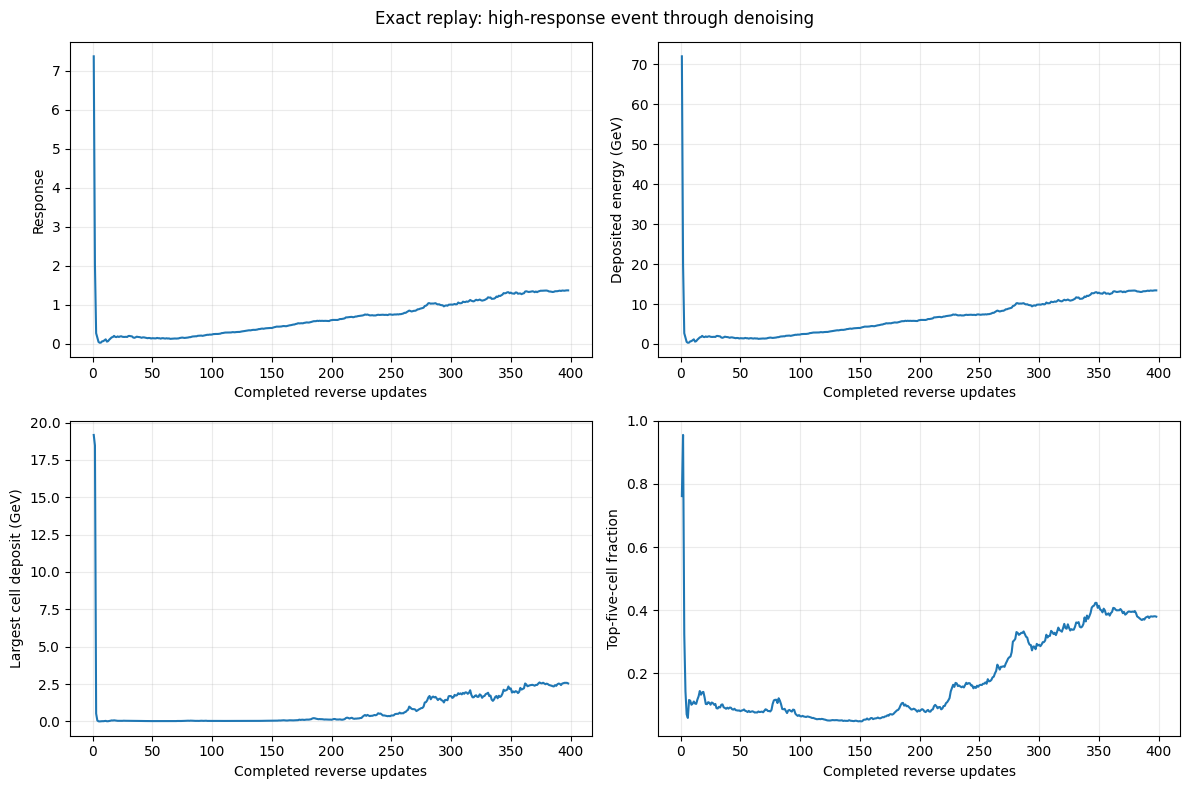

In [ ]:
# 14. Decode every x0_hat and quantify when the high response develops
if REPLAY_AVAILABLE and trace_states:
    trajectory_rows = []
    for completed, (timestep, state) in enumerate(zip(trace_timesteps, trace_states), start=1):
        native_step = decode_model_batch(state.reshape(1, -1), [high["energy"]], apply_cut=True)[0]
        obs = event_metrics(native_step, high["energy"])
        trajectory_rows.append({
            "completed_updates": completed,
            "diffusion_timestep": timestep,
            "deposit_GeV": obs["deposit_GeV"],
            "response": obs["response"],
            "occupancy": obs["occupancy"],
            "depth_layer": obs["depth_layer"],
            "r_rms_XML": obs["r_rms_XML"],
            "max_cell_GeV": obs["max_cell_GeV"],
            "top5_fraction": obs["top5_fraction"],
        })
    trajectory_df = pd.DataFrame(trajectory_rows)
    display(trajectory_df.iloc[[0, len(trajectory_df)//4, len(trajectory_df)//2, 3*len(trajectory_df)//4, len(trajectory_df)-1]])

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for ax, col, label in [
        (axes[0,0], "response", "Response"),
        (axes[0,1], "deposit_GeV", "Deposited energy (GeV)"),
        (axes[1,0], "max_cell_GeV", "Largest cell deposit (GeV)"),
        (axes[1,1], "top5_fraction", "Top-five-cell fraction"),
    ]:
        ax.plot(trajectory_df["completed_updates"], trajectory_df[col])
        ax.set_xlabel("Completed reverse updates")
        ax.set_ylabel(label)
        ax.grid(alpha=0.25)
    fig.suptitle("Exact replay: high-response event through denoising")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "high_response_decoder_trajectory.png", dpi=160)
    plt.show()
else:
    trajectory_df = pd.DataFrame()
    print("Trajectory not available: exact replay or tracing did not complete.")

In [ ]:
# 15. Final decoder path and per-cell inverse-transform consistency
if REPLAY_AVAILABLE:
    target_saved = archived["native"][HIGH_ROW].astype(np.float64)
    target_replayed = replay_native[local_target].astype(np.float64)
    target_replay_rel_l1 = float(np.abs(target_replayed-target_saved).sum()/max(np.abs(target_saved).sum(),1e-15))

    # The same stable inverse used in the validation notebook:
    # native_i = MAXDEP * E_inc * (sigmoid(logit_i)-alpha)/(1-2alpha).
    target_model_x = ordinary_model_output[local_target].detach().cpu().numpy().astype(np.float64).reshape(-1)
    target_logits = target_model_x * LOGIT_STD + LOGIT_MEAN
    target_fraction = (expit(target_logits)-1e-6)/(1-2e-6)
    reconstructed = target_fraction * MAXDEP * high["energy"]
    reconstructed = np.where(reconstructed >= ANALYSIS_CUT_GEV, reconstructed, 0.0)
    inverse_vs_saved_rel_l1 = float(np.abs(reconstructed-target_saved).sum()/max(np.abs(target_saved).sum(),1e-15))

    # Compare against the repository's own legacy decoder for the replayed batch.
    with contextlib.redirect_stdout(io.StringIO()):
        legacy_native = np.asarray(cp.to_physical(model, ordinary_model_output, replay_energies)).reshape(len(replay_energies), -1)
    legacy_native = np.where(legacy_native >= ANALYSIS_CUT_GEV, legacy_native, 0.0)
    stable_legacy_rel_l1 = float(np.abs(legacy_native[local_target]-target_replayed).sum()/max(target_replayed.sum(),1e-15))

    decoder_audit = pd.DataFrame([{
        "event_id": high["event_id"],
        "incident_energy_GeV": high["energy"],
        "saved_deposit_GeV": target_saved.sum(),
        "replayed_deposit_GeV": target_replayed.sum(),
        "saved_response": target_saved.sum()/high["energy"],
        "replayed_response": target_replayed.sum()/high["energy"],
        "replay_vs_archive_relative_L1": target_replay_rel_l1,
        "manual_inverse_vs_archive_relative_L1": inverse_vs_saved_rel_l1,
        "stable_vs_legacy_decoder_relative_L1": stable_legacy_rel_l1,
        "MAXDEP": MAXDEP,
        "per_cell_scale_MAXDEP_times_E_GeV": MAXDEP*high["energy"],
        "trace_final_matches_standard": trace_neutral,
    }])
    display(decoder_audit)
else:
    decoder_audit = pd.DataFrame()
    print("Decoder replay audit skipped because exact checkpoint/source replay was unavailable.")

,event_id,incident_energy_GeV,saved_deposit_GeV,replayed_deposit_GeV,saved_response,replayed_response,replay_vs_archive_relative_L1,manual_inverse_vs_archive_relative_L1,stable_vs_legacy_decoder_relative_L1,MAXDEP,per_cell_scale_MAXDEP_times_E_GeV,trace_final_matches_standard
0,gen:electron:8-12GeV:0:61,9.771068,13.41858,13.41858,1.373297,1.373297,1.946581e-08,1.946581e-08,3.986486e-07,2.0,19.542137,True


## 6. Fixed-cell hotspot recurrence and neighbourhood audit

The candidate hotspot is at `(layer 10, angle 13, radial 8)`, native index `1565`. We compare the exact cell, the same-layer outer radial ring, a local neighbourhood spanning layers 9–11 / angles 12–14 / radial bins 7–8 (with periodic angular wrapping), and the detector-wide outer radial shell.

The primary event samples are kept intact. This section counts threshold exceedances and reports rates with Wilson intervals; it does not label a zero count in 300 reference showers as a physical impossibility.

In [ ]:
# 16. Define hotspot and neighbourhood measurements

def local_hotspot_metrics(native):
    a = threshold_native(native)
    cube = a.reshape(N_LAYERS, N_ANGLES, N_RADIAL)
    exact = float(cube[HOTSPOT_COORD])
    layer10_outer_by_angle = cube[10, :, 8]
    local_layers = [9, 10, 11]
    local_angles = [(13-1)%16, 13, (13+1)%16]
    local_radials = [7, 8]
    local_values = cube[np.ix_(local_layers, local_angles, local_radials)]
    outer_shell = cube[:, :, 8]
    return {
        "exact_cell_1565_GeV": exact,
        "layer10_radial8_sum_GeV": float(layer10_outer_by_angle.sum()),
        "layer10_radial8_max_angle_GeV": float(layer10_outer_by_angle.max()),
        "local_neighbourhood_sum_GeV": float(local_values.sum()),
        "local_neighbourhood_max_GeV": float(local_values.max()),
        "local_neighbourhood_cells_ge_0p1": int(np.count_nonzero(local_values >= 0.1)),
        "outer_shell_sum_GeV": float(outer_shell.sum()),
    }

# Collect event-level measurements for reference, scale-only and generator.
hotspot_event_rows = []
for window in STRATA:
    # Reference and scale-only are identical across runs; use the first run only.
    for method in ("reference", "scale_only"):
        arr = runs[EXPECTED_SEEDS[0]]["data"][window][method]
        for row, (native, energy, event_id) in enumerate(zip(arr["native"], arr["energy"], arr["event_id"])):
            m = local_hotspot_metrics(native)
            hotspot_event_rows.append({
                "window":window, "method":method, "seed":"fixed", "run":-1, "row":row,
                "event_id":str(event_id), "incident_energy_GeV":float(energy), **m
            })
    for seed in EXPECTED_SEEDS:
        for run in (0, 1):
            arr = runs[seed]["data"][window][f"generator_run{run}"]
            for row, (native, energy, event_id) in enumerate(zip(arr["native"], arr["energy"], arr["event_id"])):
                m = local_hotspot_metrics(native)
                hotspot_event_rows.append({
                    "window":window, "method":"generator", "seed":seed, "run":run, "row":row,
                    "event_id":str(event_id), "incident_energy_GeV":float(energy), **m
                })
hotspot_events = pd.DataFrame(hotspot_event_rows)
print("Event-level hotspot audit rows:", len(hotspot_events))
display(hotspot_events.head())

Event-level hotspot audit rows: 7200


,window,method,seed,run,row,event_id,incident_energy_GeV,exact_cell_1565_GeV,layer10_radial8_sum_GeV,layer10_radial8_max_angle_GeV,local_neighbourhood_sum_GeV,local_neighbourhood_max_GeV,local_neighbourhood_cells_ge_0p1,outer_shell_sum_GeV
0,8-12GeV,reference,fixed,-1,0,bf73fcfa2269b3e0e0a24d0bccdeb052369fdd5ead2690...,9.535075,0.0,0.000000,0.000000,0.043764,0.043764,0,0.113649
1,8-12GeV,reference,fixed,-1,1,bf73fcfa2269b3e0e0a24d0bccdeb052369fdd5ead2690...,11.703797,0.0,0.003014,0.003014,0.000000,0.000000,0,0.076826
2,8-12GeV,reference,fixed,-1,2,bf73fcfa2269b3e0e0a24d0bccdeb052369fdd5ead2690...,11.825549,0.0,0.000000,0.000000,0.001324,0.001324,0,0.076737
3,8-12GeV,reference,fixed,-1,3,bf73fcfa2269b3e0e0a24d0bccdeb052369fdd5ead2690...,9.570952,0.0,0.000000,0.000000,0.000000,0.000000,0,0.042678
4,8-12GeV,reference,fixed,-1,4,bf73fcfa2269b3e0e0a24d0bccdeb052369fdd5ead2690...,8.296643,0.0,0.000000,0.000000,0.000000,0.000000,0,0.041289


In [ ]:
# 17. Summarise hotspot-tail rates with Wilson intervals
hotspot_summary_rows = []
metric_thresholds = {
    "exact_cell_1565_GeV": HOTSPOT_THRESHOLDS_GEV,
    "layer10_radial8_max_angle_GeV": (0.1, 0.25, 0.5, 0.8, 1.0),
    "local_neighbourhood_max_GeV": (0.1, 0.25, 0.5, 0.8, 1.0),
    "local_neighbourhood_sum_GeV": (0.5, 1.0, 2.0),
    "outer_shell_sum_GeV": (0.5, 1.0, 2.0),
}
for (window, method), group in hotspot_events.groupby(["window", "method"]):
    n = len(group)
    for metric, thresholds in metric_thresholds.items():
        vals = group[metric].to_numpy(float)
        row = {
            "window":window, "method":method, "n":n, "observable":metric,
            "mean_GeV":float(np.mean(vals)), "q95_GeV":float(np.quantile(vals,0.95)),
            "q99_GeV":float(np.quantile(vals,0.99)), "maximum_GeV":float(np.max(vals)),
        }
        for threshold in thresholds:
            k = int(np.sum(vals >= threshold))
            lo, hi = wilson_interval(k, n)
            label = str(threshold).replace(".", "p")
            row[f"count_ge_{label}"] = k
            row[f"rate_ge_{label}"] = k/n
            row[f"rate_lo_ge_{label}"] = lo
            row[f"rate_hi_ge_{label}"] = hi
        hotspot_summary_rows.append(row)
hotspot_summary = pd.DataFrame(hotspot_summary_rows)
print("Exact-cell, local neighbourhood, ring and outer-shell tail summary:")
display(hotspot_summary)

# Exact-cell exceedance events at the previously used 0.1 GeV threshold.
exact_hits = hotspot_events[hotspot_events["exact_cell_1565_GeV"] >= 0.1].copy()
print("Exact cell 1565 events with deposit >= 0.1 GeV:")
display(exact_hits.sort_values(["window","method","seed","run","row"]))

Exact-cell, local neighbourhood, ring and outer-shell tail summary:


,window,method,n,observable,mean_GeV,q95_GeV,q99_GeV,maximum_GeV,count_ge_0p1,rate_ge_0p1,...,rate_lo_ge_0p8,rate_hi_ge_0p8,count_ge_1p0,rate_ge_1p0,rate_lo_ge_1p0,rate_hi_ge_1p0,count_ge_2p0,rate_ge_2p0,rate_lo_ge_2p0,rate_hi_ge_2p0
0,40-60GeV,generator,1800,exact_cell_1565_GeV,0.001187,0.006080,0.024382,0.238223,2.0,0.001111,...,2.168404e-19,0.002130,0,0.000000,2.168404e-19,0.002130,NaN,NaN,NaN,NaN
1,40-60GeV,generator,1800,layer10_radial8_max_angle_GeV,0.013624,0.045604,0.105465,0.654520,19.0,0.010556,...,2.168404e-19,0.002130,0,0.000000,2.168404e-19,0.002130,NaN,NaN,NaN,NaN
2,40-60GeV,generator,1800,local_neighbourhood_max_GeV,0.014416,0.044476,0.119690,1.211094,23.0,0.012778,...,9.807593e-05,0.003140,1,0.000556,9.807593e-05,0.003140,NaN,NaN,NaN,NaN
3,40-60GeV,generator,1800,local_neighbourhood_sum_GeV,0.021260,0.075235,0.145456,1.212273,NaN,NaN,...,NaN,NaN,1,0.000556,9.807593e-05,0.003140,0.0,0.000000,2.168404e-19,0.002130
4,40-60GeV,generator,1800,outer_shell_sum_GeV,0.417110,0.741227,1.065488,3.441618,NaN,NaN,...,NaN,NaN,23,0.012778,8.529495e-03,0.019101,3.0,0.001667,5.669754e-04,0.004889
5,40-60GeV,reference,300,exact_cell_1565_GeV,0.000907,0.004794,0.019603,0.060654,0.0,0.000000,...,8.673617e-19,0.012643,0,0.000000,8.673617e-19,0.012643,NaN,NaN,NaN,NaN
6,40-60GeV,reference,300,layer10_radial8_max_angle_GeV,0.012901,0.041509,0.079959,0.540201,2.0,0.006667,...,8.673617e-19,0.012643,0,0.000000,8.673617e-19,0.012643,NaN,NaN,NaN,NaN
7,40-60GeV,reference,300,local_neighbourhood_max_GeV,0.016268,0.055345,0.138890,0.360317,6.0,0.020000,...,8.673617e-19,0.012643,0,0.000000,8.673617e-19,0.012643,NaN,NaN,NaN,NaN
8,40-60GeV,reference,300,local_neighbourhood_sum_GeV,0.023947,0.081570,0.261402,0.429412,NaN,NaN,...,NaN,NaN,0,0.000000,8.673617e-19,0.012643,0.0,0.000000,8.673617e-19,0.012643
9,40-60GeV,reference,300,outer_shell_sum_GeV,0.456540,0.851510,1.197920,1.567179,NaN,NaN,...,NaN,NaN,7,0.023333,1.134766e-02,0.047372,0.0,0.000000,8.673617e-19,0.012643


Exact cell 1565 events with deposit >= 0.1 GeV:


,window,method,seed,run,row,event_id,incident_energy_GeV,exact_cell_1565_GeV,layer10_radial8_sum_GeV,layer10_radial8_max_angle_GeV,local_neighbourhood_sum_GeV,local_neighbourhood_max_GeV,local_neighbourhood_cells_ge_0p1,outer_shell_sum_GeV
3147,40-60GeV,generator,20261110,0,147,gen:electron:40-60GeV:0:147,41.008715,0.238223,0.238223,0.238223,0.310883,0.238223,1,0.613132
3827,40-60GeV,generator,20261111,0,227,gen:electron:40-60GeV:0:227,57.197285,0.128014,0.129466,0.128014,0.180591,0.128014,1,0.697430
1400,8-12GeV,generator,20261111,0,200,gen:electron:8-12GeV:0:200,8.448531,0.882544,0.882544,0.882544,0.973771,0.882544,1,1.037118
5666,80-120GeV,generator,20261110,0,266,gen:electron:80-120GeV:0:266,101.642039,0.299178,0.315712,0.299178,0.407837,0.299178,1,1.371088
6936,80-120GeV,generator,20261112,1,36,gen:electron:80-120GeV:1:36,91.474383,0.207447,0.246809,0.207447,0.230342,0.207447,1,0.946410
7057,80-120GeV,generator,20261112,1,157,gen:electron:80-120GeV:1:157,119.102312,0.124290,0.157194,0.124290,0.224077,0.124290,1,1.005687


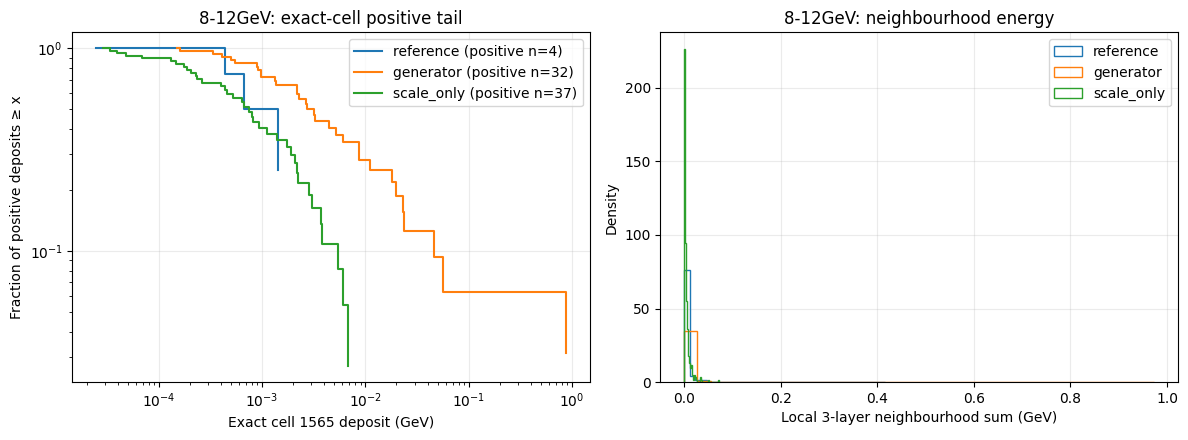

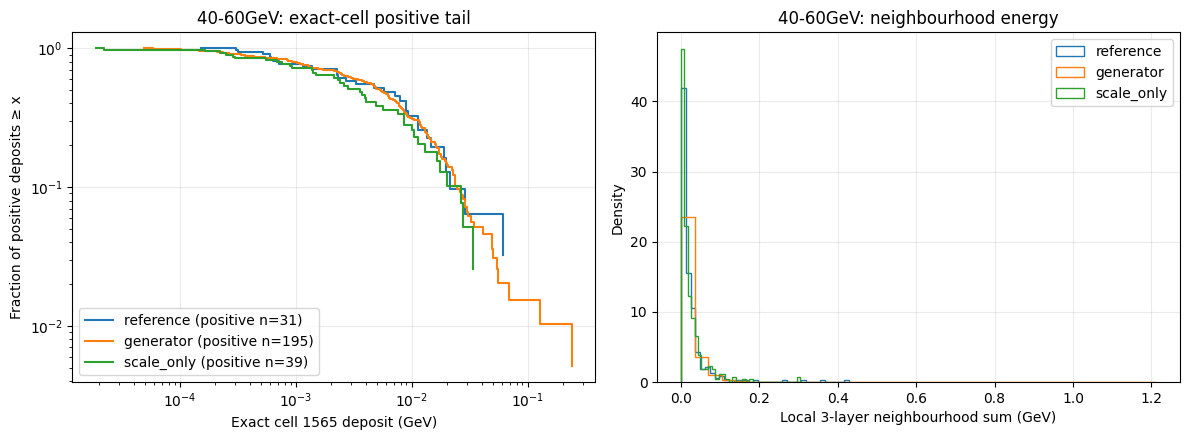

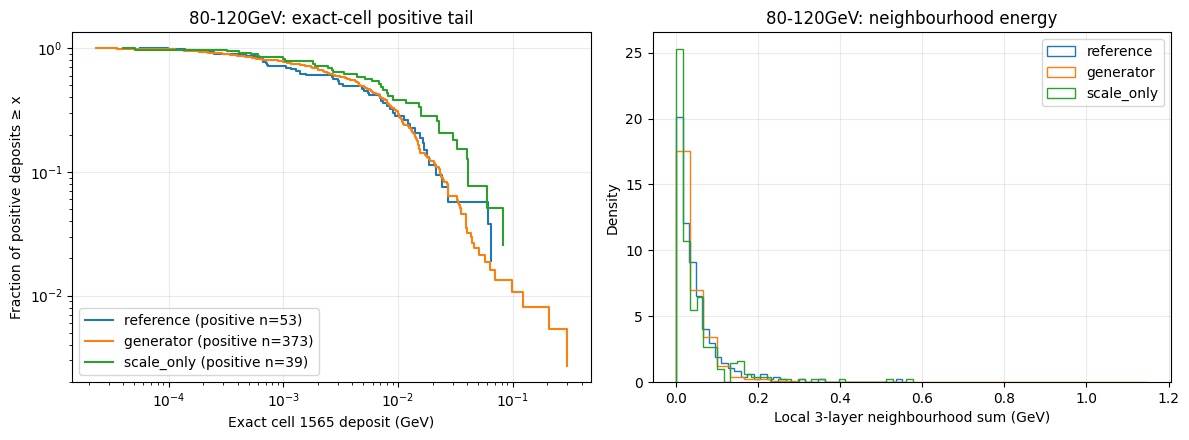

Low-response event's local 3×3×2 neighbourhood:


,layer,angle,radial_bin,native_index,energy_GeV,is_target_cell
9,10,13,8,1565,0.882544,True
3,9,13,8,1421,0.054499,False
2,9,13,7,1420,0.030646,False
6,10,12,7,1555,0.006082,False
1,9,12,8,1412,0.000000,False
0,9,12,7,1411,0.000000,False
5,9,14,8,1430,0.000000,False
4,9,14,7,1429,0.000000,False
7,10,12,8,1556,0.000000,False
8,10,13,7,1564,0.000000,False


,case,deposit_GeV,response,r_rms_XML
0,original,3.942201,0.466614,23.429949
1,remove_target_cell_only_diagnostic,3.059657,0.362153,16.021592
2,remove_local_neighbourhood_diagnostic,2.968430,0.351355,14.861013


In [ ]:
# 18. Plot hotspot distributions and inspect the candidate's neighbours
for window in STRATA:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    subset = hotspot_events[hotspot_events.window == window]
    for method in ("reference", "generator", "scale_only"):
        vals = subset.loc[subset.method == method, "exact_cell_1565_GeV"].to_numpy(float)
        positive = np.sort(vals[vals > 0])
        if len(positive):
            survival = np.arange(len(positive), 0, -1) / len(positive)
            axes[0].step(positive, survival, where="post", label=f"{method} (positive n={len(positive)})")
    axes[0].set_xscale("log"); axes[0].set_yscale("log")
    axes[0].set_xlabel("Exact cell 1565 deposit (GeV)")
    axes[0].set_ylabel("Fraction of positive deposits ≥ x")
    axes[0].set_title(f"{window}: exact-cell positive tail")
    axes[0].grid(alpha=0.25); axes[0].legend()

    for method in ("reference", "generator", "scale_only"):
        vals = subset.loc[subset.method == method, "local_neighbourhood_sum_GeV"].to_numpy(float)
        axes[1].hist(vals, bins=35, density=True, histtype="step", label=method)
    axes[1].set_xlabel("Local 3-layer neighbourhood sum (GeV)")
    axes[1].set_ylabel("Density")
    axes[1].set_title(f"{window}: neighbourhood energy")
    axes[1].grid(alpha=0.25); axes[1].legend()
    fig.tight_layout(); fig.savefig(FIG_DIR / f"hotspot_{window}.png", dpi=160); plt.show()

low = candidate_data["low_response_broad_radial_0p467"]
low_cube = low["obs"]["native_after_cut"].reshape(N_LAYERS, N_ANGLES, N_RADIAL)
L, A, R = HOTSPOT_COORD
neighbour_rows = []
for l in (L-1, L, L+1):
    for a in ((A-1)%N_ANGLES, A, (A+1)%N_ANGLES):
        for r in (R-1, R):
            idx = int(np.ravel_multi_index((l,a,r),(N_LAYERS,N_ANGLES,N_RADIAL),order="C"))
            neighbour_rows.append({"layer":l,"angle":a,"radial_bin":r,"native_index":idx,
                                   "energy_GeV":float(low_cube[l,a,r]),"is_target_cell":idx==HOTSPOT_INDEX})
neighbour_table = pd.DataFrame(neighbour_rows).sort_values("energy_GeV",ascending=False)
print("Low-response event's local 3×3×2 neighbourhood:")
display(neighbour_table)

# Cell-removal tests are sensitivity diagnostics, not revised shower outputs.
low_original = low["obs"]["native_after_cut"].copy()
local_indices = neighbour_table["native_index"].to_numpy(int)
low_no_target = low_original.copy(); low_no_target[HOTSPOT_INDEX] = 0.0
low_no_local = low_original.copy(); low_no_local[local_indices] = 0.0

def radial_rms_from_flat(native):
    total = native.sum()
    if total <= 0: return np.nan
    return float(np.sqrt(np.sum(native * R_GRID.reshape(-1)**2) / total))

low_sensitivity = pd.DataFrame([
    {"case":"original", "deposit_GeV":low_original.sum(), "response":low_original.sum()/low["energy"], "r_rms_XML":radial_rms_from_flat(low_original)},
    {"case":"remove_target_cell_only_diagnostic", "deposit_GeV":low_no_target.sum(), "response":low_no_target.sum()/low["energy"], "r_rms_XML":radial_rms_from_flat(low_no_target)},
    {"case":"remove_local_neighbourhood_diagnostic", "deposit_GeV":low_no_local.sum(), "response":low_no_local.sum()/low["energy"], "r_rms_XML":radial_rms_from_flat(low_no_local)},
])
display(low_sensitivity)

## 7. Deep-shower candidates: matched reference distributions and layer profiles

The three candidates are compared with the fixed reference sample in the same energy window. The 45 layer axis is an **active-layer ordinal**, not a physical longitudinal distance. A candidate beyond the reference sample maximum is a sample-relative anomaly, not proof of physical impossibility.

In [ ]:
# 19. Build layer profiles and event-level depth comparisons
DEEP_LABELS = ("deep_8_12", "deep_40_60", "deep_80_120")
deep_rows = []
deep_profile_rows = []
deep_reference_bands = {}

for label in DEEP_LABELS:
    c = candidate_data[label]
    seed = c["seed"]
    window = c["window"]
    reference = runs[seed]["data"][window]["reference"]
    ref_metrics = [event_metrics(x,e) for x,e in zip(reference["native"], reference["energy"])]
    ref_depth = np.array([x["depth_layer"] for x in ref_metrics], dtype=float)
    ref_depth = ref_depth[np.isfinite(ref_depth)]
    cand = c["obs"]
    percentile = percentile_rank(ref_depth, cand["depth_layer"])
    ref_layer = np.stack([x["layer_fraction"] for x in ref_metrics])
    q25, q50, q75 = np.nanquantile(ref_layer, [0.25,0.50,0.75], axis=0)
    cand_layer = cand["layer_fraction"]
    deep_reference_bands[label] = (q25,q50,q75,cand_layer)

    deep_rows.append({
        "label":label, "seed":seed, "window":window, "event_id":c["event_id"],
        "incident_energy_GeV":c["energy"], "response":cand["response"],
        "depth_layer":cand["depth_layer"], "reference_depth_median":float(np.median(ref_depth)),
        "reference_depth_q95":float(np.quantile(ref_depth,0.95)),
        "reference_depth_q99":float(np.quantile(ref_depth,0.99)),
        "reference_depth_max":float(np.max(ref_depth)),
        "candidate_depth_percentile":percentile,
        "r_rms_XML":cand["r_rms_XML"],
        "reference_r_rms_q99":float(np.quantile([x["r_rms_XML"] for x in ref_metrics if np.isfinite(x["r_rms_XML"])],0.99)),
        "peak_layer":int(np.argmax(cand["layer_energy_GeV"])),
        "early_fraction_0_9":float(cand_layer[:10].sum()),
        "middle_fraction_10_24":float(cand_layer[10:25].sum()),
        "late_fraction_25_44":float(cand_layer[25:].sum()),
    })
    for layer in range(N_LAYERS):
        deep_profile_rows.append({
            "candidate":label,"window":window,"layer_ordinal":layer,
            "reference_q25":q25[layer],"reference_median":q50[layer],"reference_q75":q75[layer],
            "candidate_fraction":cand_layer[layer],
        })

deep_summary = pd.DataFrame(deep_rows)
deep_profiles = pd.DataFrame(deep_profile_rows)
display(deep_summary)

,label,seed,window,event_id,incident_energy_GeV,response,depth_layer,reference_depth_median,reference_depth_q95,reference_depth_q99,reference_depth_max,candidate_depth_percentile,r_rms_XML,reference_r_rms_q99,peak_layer,early_fraction_0_9,middle_fraction_10_24,late_fraction_25_44
0,deep_8_12,20261110,8-12GeV,gen:electron:8-12GeV:1:58,10.399022,0.735014,22.527751,8.551850,11.365880,13.365178,31.943524,99.666667,7.127536,16.937494,21,0.039295,0.546783,0.413922
1,deep_40_60,20261110,40-60GeV,gen:electron:40-60GeV:0:113,43.047789,0.745916,16.845594,10.560139,12.737548,14.362103,15.385411,100.000000,12.390800,13.333534,17,0.188496,0.644935,0.166569
2,deep_80_120,20261112,80-120GeV,gen:electron:80-120GeV:1:48,114.937406,0.783482,16.712123,11.566918,13.568134,14.624557,16.032087,100.000000,11.023454,12.660584,18,0.133066,0.760683,0.106251


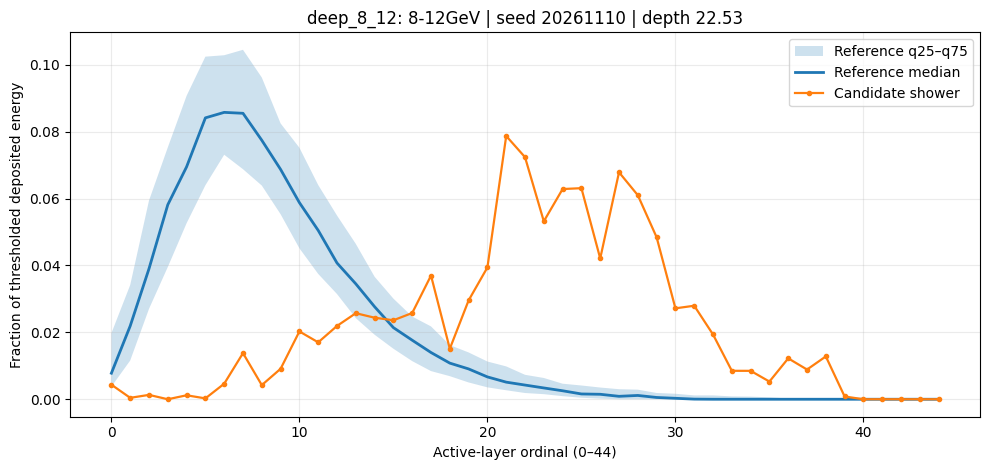

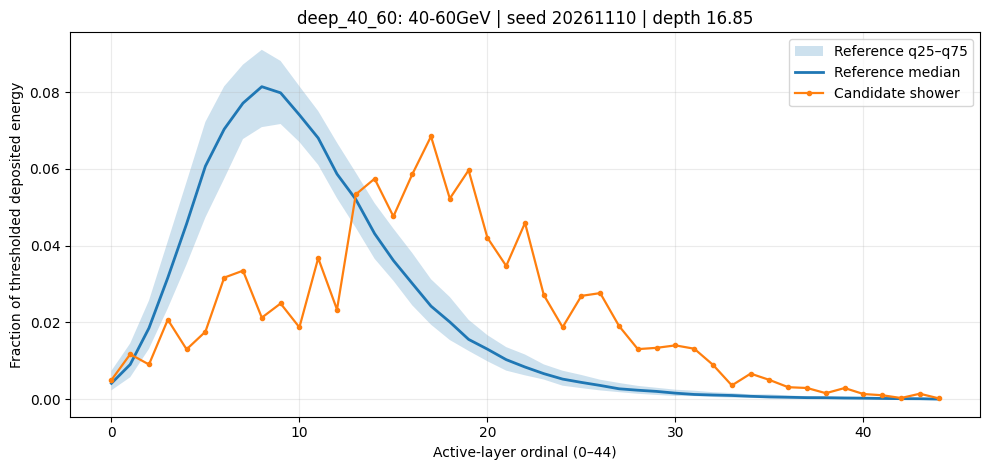

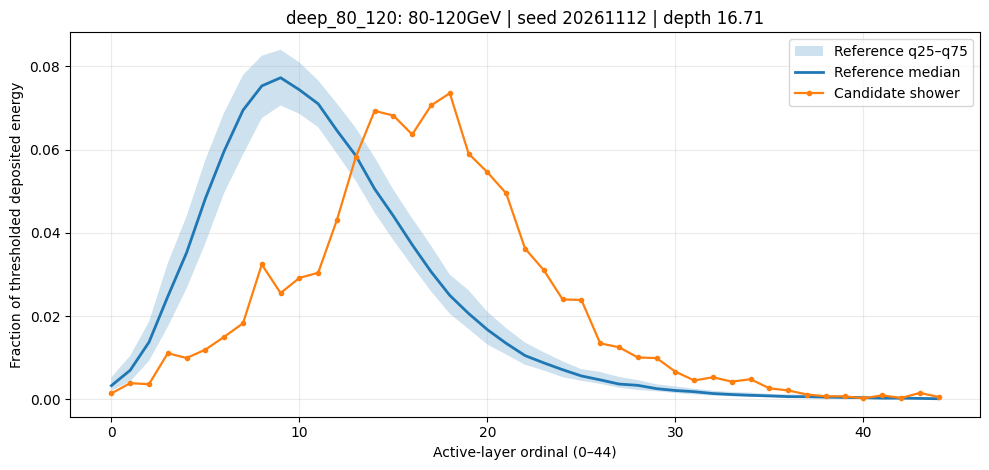

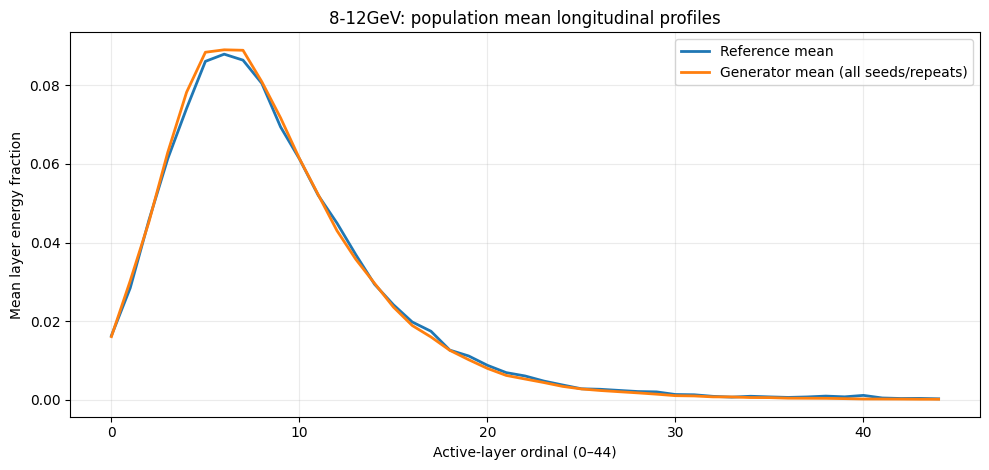

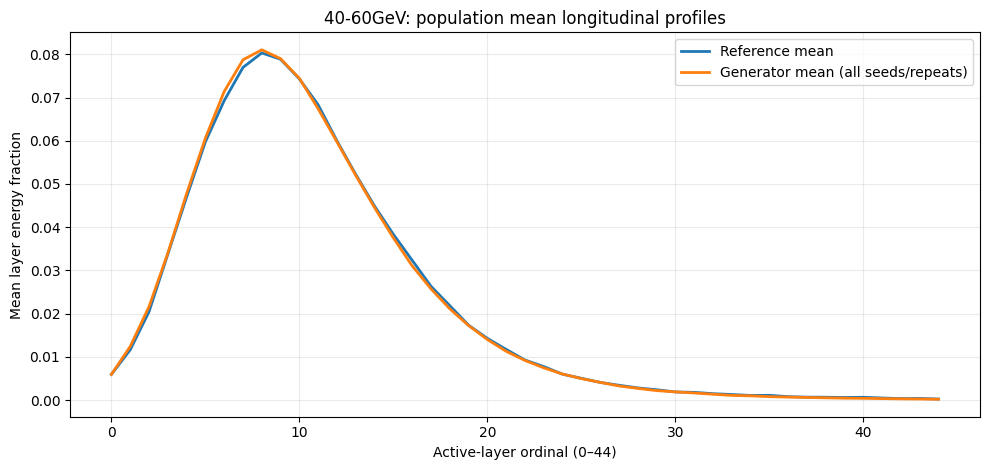

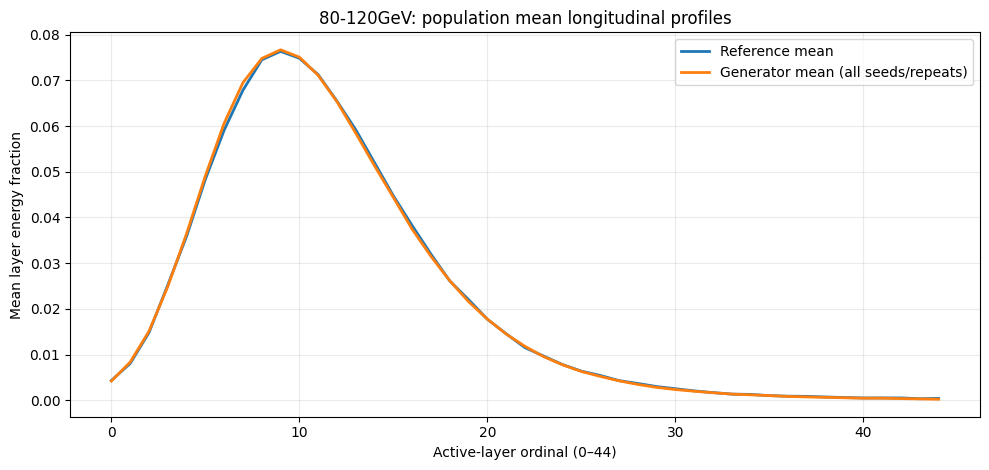

In [ ]:
# 20. Plot candidate profiles against the reference interquartile range
for label in DEEP_LABELS:
    c = candidate_data[label]
    q25,q50,q75,cand_layer = deep_reference_bands[label]
    layers = np.arange(N_LAYERS)
    fig, ax = plt.subplots(figsize=(10,4.8))
    ax.fill_between(layers,q25,q75,alpha=0.22,label="Reference q25–q75")
    ax.plot(layers,q50,linewidth=2,label="Reference median")
    ax.plot(layers,cand_layer,marker="o",markersize=3,linewidth=1.6,label="Candidate shower")
    ax.set_xlabel("Active-layer ordinal (0–44)")
    ax.set_ylabel("Fraction of thresholded deposited energy")
    ax.set_title(f"{label}: {c['window']} | seed {c['seed']} | depth {c['obs']['depth_layer']:.2f}")
    ax.grid(alpha=0.25); ax.legend(); fig.tight_layout()
    fig.savefig(FIG_DIR / f"{label}_reference_profile.png", dpi=160)
    plt.show()

# Plot the average layer profile for all seeds beside fixed reference.
for window in STRATA:
    ref = runs[EXPECTED_SEEDS[0]]["data"][window]["reference"]
    ref_profiles = np.stack([event_metrics(x,e)["layer_fraction"] for x,e in zip(ref["native"],ref["energy"])])
    gen_profiles = []
    for seed in EXPECTED_SEEDS:
        for run in (0,1):
            arr = runs[seed]["data"][window][f"generator_run{run}"]
            gen_profiles.extend([event_metrics(x,e)["layer_fraction"] for x,e in zip(arr["native"],arr["energy"])])
    gen_profiles = np.asarray(gen_profiles)
    layers = np.arange(N_LAYERS)
    fig, ax = plt.subplots(figsize=(10,4.8))
    ax.plot(layers,np.nanmean(ref_profiles,axis=0),label="Reference mean",linewidth=2)
    ax.plot(layers,np.nanmean(gen_profiles,axis=0),label="Generator mean (all seeds/repeats)",linewidth=2)
    ax.set_xlabel("Active-layer ordinal (0–44)"); ax.set_ylabel("Mean layer energy fraction")
    ax.set_title(f"{window}: population mean longitudinal profiles")
    ax.grid(alpha=0.25); ax.legend(); fig.tight_layout()
    fig.savefig(FIG_DIR / f"{window}_population_layer_profile.png", dpi=160)
    plt.show()

## 8. Reference-data provenance: what the archives can and cannot tell us

The manifests show the reference HDF5 path/hash and checkpoint path/hash, while the Dataset 2 configuration records intended training/evaluation file names. The ZIPs do **not** preserve the full mapping from the 12,000-row local reference cache back to official event IDs or checkpoint-selection history. Therefore this notebook cannot mark the sample as checkpoint-unseen.

In [ ]:
# 21. Create a provenance evidence sheet for discussion with your guide
base_manifest = runs[EXPECTED_SEEDS[0]]["manifest"]
provenance_rows = [
    {
        "question":"Which exact source file produced the 12,000-row local electron reference cache?",
        "archive_evidence":base_manifest["reference_files"]["electron"].get("path", "not recorded"),
        "required_confirmation":"Exact source HDF5 filename, split name, row/event mapping and extraction script.",
        "status":"UNRESOLVED", "guide_answer":""
    },
    {
        "question":"Were these 12,000 events excluded from checkpoint gradient training?",
        "archive_evidence":"Checkpoint hash is recorded; event-level training membership is not.",
        "required_confirmation":"Training event IDs or a documented disjoint split.",
        "status":"UNRESOLVED", "guide_answer":""
    },
    {
        "question":"Were these events excluded from checkpoint selection/early stopping/model choice?",
        "archive_evidence":"No checkpoint-selection event history in the ZIP.",
        "required_confirmation":"Validation/model-selection split and event IDs.",
        "status":"UNRESOLVED", "guide_answer":""
    },
    {
        "question":"Does the checkpoint hash correspond to the checkpoint used in the three fidelity runs?",
        "archive_evidence":base_manifest["checkpoints"]["electron"]["sha256"],
        "required_confirmation":"Guide/provider confirms checkpoint provenance and training split.",
        "status":"HASH_MATCHED_ACROSS_RUNS; TRAINING_HISTORY_UNRESOLVED", "guide_answer":""
    },
    {
        "question":"Is the original row-to-event mapping for the local cache preserved?",
        "archive_evidence":"Fidelity partition IDs use cache fingerprint plus row index.",
        "required_confirmation":"Original official event IDs or extraction manifest.",
        "status":"UNRESOLVED", "guide_answer":""
    },
]
provenance_df = pd.DataFrame(provenance_rows)
display(provenance_df)
print("Do not change reference_is_unseen_by_checkpoint to True unless these items are documented.")

,question,archive_evidence,required_confirmation,status,guide_answer
0,"Which exact source file produced the 12,000-ro...",/content/gen-hep-notebooks/capstone/calodiffus...,"Exact source HDF5 filename, split name, row/ev...",UNRESOLVED,
1,"Were these 12,000 events excluded from checkpo...",Checkpoint hash is recorded; event-level train...,Training event IDs or a documented disjoint sp...,UNRESOLVED,
2,Were these events excluded from checkpoint sel...,No checkpoint-selection event history in the ZIP.,Validation/model-selection split and event IDs.,UNRESOLVED,
3,Does the checkpoint hash correspond to the che...,cb62afae47997307842a3f7683fcbeffdbfc7db7a7a86b...,Guide/provider confirms checkpoint provenance ...,HASH_MATCHED_ACROSS_RUNS; TRAINING_HISTORY_UNR...,
4,Is the original row-to-event mapping for the l...,Fidelity partition IDs use cache fingerprint p...,Original official event IDs or extraction mani...,UNRESOLVED,


Do not change reference_is_unseen_by_checkpoint to True unless these items are documented.


## 9. Export the final electron technical-action package

The final archive contains the replay comparison/trajectory (when available), high-response cell ranking, hotspot recurrence and event IDs, low-response neighbourhood audit, deep-candidate reference comparisons, plots and provenance questions.

In [ ]:
# 22. Save results and write a concise report
# Data tables
compat_df.to_csv(TABLE_DIR / "run_compatibility.csv", index=False)
candidate_summary_df.to_csv(TABLE_DIR / "candidate_summary.csv", index=False)
high_top_cells.to_csv(TABLE_DIR / "high_response_top_cells.csv", index=False)
high_sensitivity.to_csv(TABLE_DIR / "high_response_sensitivity.csv", index=False)
hotspot_events.to_csv(TABLE_DIR / "hotspot_event_level.csv", index=False)
hotspot_summary.to_csv(TABLE_DIR / "hotspot_recurrence_summary.csv", index=False)
exact_hits.to_csv(TABLE_DIR / "exact_hotspot_occurrences_ge_0p1GeV.csv", index=False)
neighbour_table.to_csv(TABLE_DIR / "low_response_hotspot_neighbours.csv", index=False)
low_sensitivity.to_csv(TABLE_DIR / "low_response_sensitivity.csv", index=False)
deep_summary.to_csv(TABLE_DIR / "deep_candidate_reference_comparison.csv", index=False)
deep_profiles.to_csv(TABLE_DIR / "deep_candidate_layer_profiles.csv", index=False)
provenance_df.to_csv(TABLE_DIR / "reference_provenance_questions.csv", index=False)
if not source_hash_df.empty: source_hash_df.to_csv(TABLE_DIR / "exact_replay_source_hash_audit.csv", index=False)
if dataset2_config_evidence: (OUTPUT_DIR / "dataset2_config_file_role_evidence.json").write_text(json.dumps(dataset2_config_evidence, indent=2))
if not replay_comparison.empty: replay_comparison.to_csv(TABLE_DIR / "high_response_exact_replay_comparison.csv", index=False)
if not decoder_audit.empty: decoder_audit.to_csv(TABLE_DIR / "high_response_decoder_audit.csv", index=False)
if not trajectory_df.empty: trajectory_df.to_csv(TABLE_DIR / "high_response_decoder_trajectory.csv", index=False)

report = []
report.append("# Electron Final Technical Actions Report")
report.append("")
report.append(f"Generation seeds: {list(EXPECTED_SEEDS)}")
report.append(f"Analysis cutoff: {ANALYSIS_CUT_GEV:g} GeV")
report.append(f"Hotspot: native cell {HOTSPOT_INDEX} at {HOTSPOT_COORD}")
report.append("")
report.append("## Compatibility")
report.append(f"All recorded compatibility checks passed: {bool(compat_df['passed'].all())}.")
report.append("Reference/checkpoint independence remains unverified.")
report.append("")
report.append("## High-response replay")
if not decoder_audit.empty:
    report.append(decoder_audit.to_string(index=False))
    report.append(f"Exact replay matched archive within relative-L1 tolerance: {bool(replay_match)}.")
    report.append(f"Trace final state matches ordinary generation: {bool(trace_neutral)}.")
else:
    report.append(f"Exact replay unavailable: {REPLAY_SETUP_ERROR}")
report.append("")
report.append("## Hotspot recurrence")
for w in STRATA:
    gen = hotspot_events[(hotspot_events.window==w)&(hotspot_events.method=="generator")]
    k = int((gen["exact_cell_1565_GeV"] >= 0.1).sum())
    report.append(f"- {w}: exact cell 1565 >=0.1 GeV in {k}/{len(gen)} generated showers.")
report.append("Interpret these as rare-event counts; reference sample maxima are not physical bounds.")
report.append("")
report.append("## Deep candidates")
report.append(deep_summary[["label","response","depth_layer","reference_depth_q99","reference_depth_max","candidate_depth_percentile"]].to_string(index=False))
report.append("")
report.append("## Provenance")
report.append("Checkpoint/reference training and model-selection independence is unresolved and must be confirmed externally.")
report_path = OUTPUT_DIR / "electron_final_technical_actions_report.md"
report_path.write_text("\n".join(report))

# Save a machine-readable summary.
summary_json = {
    "generation_seeds": list(EXPECTED_SEEDS),
    "analysis_cut_GeV": ANALYSIS_CUT_GEV,
    "compatibility_all_passed": bool(compat_df["passed"].all()),
    "exact_replay_available": bool(REPLAY_AVAILABLE),
    "exact_replay_archive_match": bool(replay_match),
    "trace_neutral": bool(trace_neutral),
    "replay_setup_error": REPLAY_SETUP_ERROR,
    "hotspot_native_index": HOTSPOT_INDEX,
    "reference_independence_verified": False,
}
(OUTPUT_DIR / "summary.json").write_text(json.dumps(summary_json, indent=2))

# Archive outputs.
archive_path = Path("/content/electron_final_technical_actions_results.zip")
with zipfile.ZipFile(archive_path, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=4) as z:
    for p in OUTPUT_DIR.rglob("*"):
        if p.is_file(): z.write(p, p.relative_to(OUTPUT_DIR.parent))
print("Saved report:", report_path)
print("Saved results archive:", archive_path)

Saved report: /content/electron_final_actions/electron_final_technical_actions_report.md
Saved results archive: /content/electron_final_technical_actions_results.zip


In [ ]:
# 23. Download the final results archive (Google Colab)
from google.colab import files
files.download(str(archive_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. How to decide whether the electron diagnostics are closed

### Decoder replay
- **Strong pass:** exact source/checkpoint hashes match, traced-vs-ordinary sampler output agrees, and replayed decoded batch agrees with archived native arrays within the stated tolerance.
- **Not established:** source/checkpoint retrieval fails or replay does not reproduce the archived sample. Do not infer a decoder bug from this; first resolve version, hardware and deterministic-kernel differences.
- Inspect the per-step `x0_hat` trajectory to see when response, maximum cell deposit and top-five-cell concentration become large. This can localise the onset of the anomaly, but does not by itself identify a physical cause.

### Fixed-cell hotspot
- Compare exact-cell, local-neighbourhood, layer-10 outer-ring and whole-outer-shell distributions.
- A rare exact-cell event with otherwise ordinary neighbourhood/shell statistics indicates a localised event, not a general shower-width problem.
- Keep all showers in the fidelity sample. Cell removal is only a diagnostic sensitivity calculation.

### Deep showers
- Compare each candidate with the same-energy reference depth distribution and all 45 layer fractions.
- A candidate beyond the 300-event reference maximum is unusual relative to this sample, not automatically physically impossible.

### Provenance
- The notebook cannot prove checkpoint-training independence from the fidelity archives. Keep the benchmark labelled preliminary until the guide/provider supplies the training and model-selection event provenance.